# Fine tuned Pretrained Model

This Jupyter Notebook contains an image recognition model that consists of a fine tuned and pretrained `VGG16` model and some additional layers. The model is trained to recognize four different types of dinnerware items from images. The model is created using the `Keras` library with `TesnsorFlow` as the backend. 

`Matplotlib.pyplot` and `NumPy` libraries are used for formatting and visualising data and performance results. `Time` library provides a method for measuring the model's training time. The `Scikit Learn` library is used to calculate performance metrics and also to display them more visually.

In [1]:
import os, shutil, pathlib
os.environ["KERAS_BACKEND"] = "tensorflow"

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, accuracy_score, ConfusionMatrixDisplay, classification_report
import time

keras.utils.set_random_seed(2)

Using the `keras.utils.set_random_seed` function reduces the difference between different runs so that performance results are more similar if the model is created and trained again. 

## Data Preprocessing

The dataset used for the training contains images of four different types of dinnerware items: bowls, drinking glasses, mugs and plates. The images were preprocessed using Python wiht function from the `Pillow (PIL)` library. The images were cropped, resized, converted to RGB and renamed with code. For a more detailed description of the dataset refer to the `Assignment2_raport.ipynb` notebook.

The dataset is fetched from the base folder using the `pathlib.Path` class and Keras library's `image_dataset_from_directory` function. For the function to work correctly the dinnerware images need to be divided in their own folders with aproriate class names. The function is used three times to get subsets for training, validation and testing. The `batch_size` is 32 and `image_size` is 224x224 pixels. The `seed` parameter ensures that the initial shuffle of the datasets is always the same increasing reproducbility.

In [2]:
base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

train_dataset = image_dataset_from_directory(
    base_dir / "train",
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    image_size = (224, 224),
    batch_size = 32,
    shuffle=False,
    seed=123,
)

for data_batch, labels_batch in train_dataset:
    print("Data batch shape:", data_batch.shape)
    print("Labels batch shape:", labels_batch.shape)
    break

Found 296 files belonging to 4 classes.
Found 93 files belonging to 4 classes.
Found 95 files belonging to 4 classes.
Data batch shape: (32, 224, 224, 3)
Labels batch shape: (32,)


The training set has 296 images, the validation set has 93 images and the test set has 95 images. A batch has 32 images wiht 224 x 224 dimension and they are RGB colour images that contain three colour channels. This explains the batch shape: (32, 224, 224, 3).

Below are some examples of the images in the training dataset with their labels or class names.

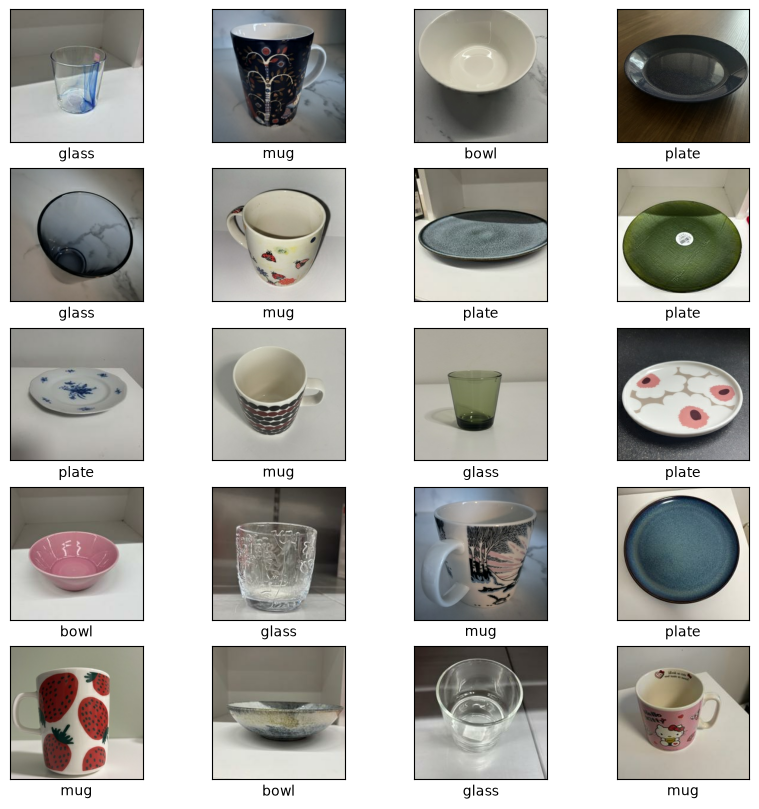

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

class_names = train_dataset.class_names

for images, labels in train_dataset.take(1):
    for i in range(20):
        plt.subplot(5, 4, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)

        plt.imshow(images[i].numpy().astype("uint8"))
        plt.xlabel(class_names[labels[i]])

plt.show()

## Modeling (1.)

The pretrained `VGG16` convolutional base is loaded with weights trained on the ImageNet dataset. VGG16 was trained with 224x224 images, which is the same size as our images. The convolutional base consists of consecutive `Conv2D` and `MaxPooling2D` layers.

Using a pretrained model reduces training time and improves accuracy compared to training a model from scratch. VGG16 has already learned general features, like edges, shapes and textures, from the large ImageNet dataset. This is especially useful because our dataset is small.

The model is trained in two phases. First, the convolutional base is frozen and only the new layers on top are trained. Then, in the fine-tuning phase, the last layers of the convolutional base are unfrozen and trained together with the new layers, so that they adapt better to our images.

In [4]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)

conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

The VGG16 convolutional base has 14,714,688 parameters. None of them are trainable, because the base is frozen. This keeps the pretrained weights from changing while the new layers are trained.

Next, a new model is made. It has a data augmentation layer, VGG16's `preprocess_input`, the VGG16 convolutional base, and `Flatten`, `Dense` and `Dropout` layers.

In [5]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
        layers.RandomBrightness(0.1)
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,138,500 (80.64 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

The model has 21,138,500 parameters in total, of which 6,423,812 are trainable and 14,714,688 are non-trainable. The non-trainable parameters belong to the frozen VGG16 convolutional base.

## Compile and Train Model (2.)

In [6]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

In [7]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning_(feature_extraction).keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True)
]

t0 = time.time()

history = model.fit(
    train_dataset,
    epochs=70,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/70


/opt/anaconda3/envs/keras/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


10/10 ━━━━━━━━━━━━━━━━━━━━ 22s 2s/step - accuracy: 0.4426 - loss: 7.0105 - val_accuracy: 0.7742 - val_loss: 1.8536
Epoch 2/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.7534 - loss: 2.1357 - val_accuracy: 0.8280 - val_loss: 2.1766
Epoch 3/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.7939 - loss: 1.3494 - val_accuracy: 0.8710 - val_loss: 1.2960
Epoch 4/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.8818 - loss: 0.6980 - val_accuracy: 0.8495 - val_loss: 1.1000
Epoch 5/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9223 - loss: 0.4477 - val_accuracy: 0.8602 - val_loss: 0.9502
Epoch 6/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9358 - loss: 0.3886 - val_accuracy: 0.9032 - val_loss: 1.0373
Epoch 7/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9662 - loss: 0.0752 - val_accuracy: 0.8817 - val_loss: 0.8927
Epoch 8/70
10/10 ━━━━━━━━━━━━━━━━━━━━ 21s 2s/step - accuracy: 0.9493 - loss: 0.2236 - val_accuracy: 0.8602 - val_loss: 0.7326
Epo

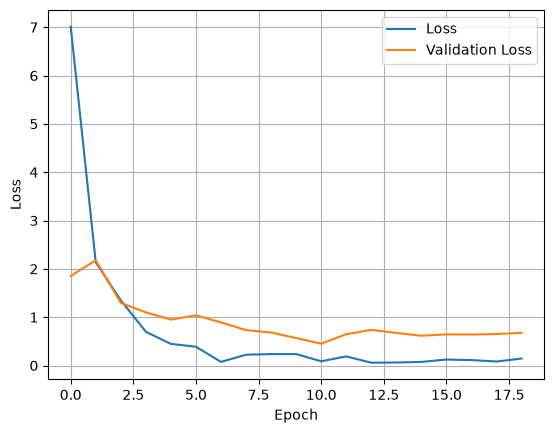

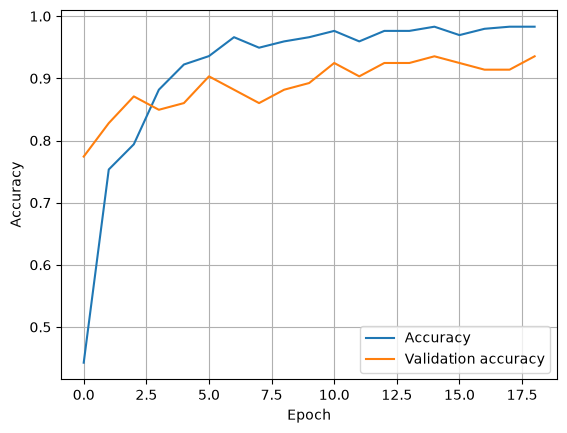

In [8]:
plt.plot(history.history["loss"], label="Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history.history["accuracy"], label="Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

In [9]:
val_model = keras.models.load_model("fine_tuning_(feature_extraction).keras")
val_loss, val_acc = val_model.evaluate(validation_dataset)

print(f"Validation accuracy: {val_acc:.3f}")
print(f"Validation loss: {val_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9247 - loss: 0.4516
Validation accuracy: 0.925
Validation loss: 0.452


## Fine Tuning Phase 

In [10]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
    
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])


In [11]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss"),
    keras.callbacks.EarlyStopping(
        monitor="val_loss", 
        patience=8, 
        restore_best_weights=True)
]

t0 = time.time()

history_2 = model.fit(
    train_dataset,
    epochs=50,
    validation_data=validation_dataset,
    callbacks=callbacks)

train_time = time.time() - t0
print(f"Training time: {train_time:.1f} s")

Epoch 1/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.9865 - loss: 0.0522 - val_accuracy: 0.9140 - val_loss: 0.5302
Epoch 2/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9696 - loss: 0.0672 - val_accuracy: 0.9032 - val_loss: 0.5092
Epoch 3/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9831 - loss: 0.1203 - val_accuracy: 0.9032 - val_loss: 0.5928
Epoch 4/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 25s 2s/step - accuracy: 0.9764 - loss: 0.0706 - val_accuracy: 0.9032 - val_loss: 0.4863
Epoch 5/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9797 - loss: 0.0982 - val_accuracy: 0.9140 - val_loss: 0.4542
Epoch 6/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9797 - loss: 0.0965 - val_accuracy: 0.9355 - val_loss: 0.4155
Epoch 7/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9831 - loss: 0.0406 - val_accuracy: 0.9355 - val_loss: 0.3697
Epoch 8/50
10/10 ━━━━━━━━━━━━━━━━━━━━ 24s 2s/step - accuracy: 0.9797 - loss: 0.0737 - val_accuracy: 0.9247 - val_loss:

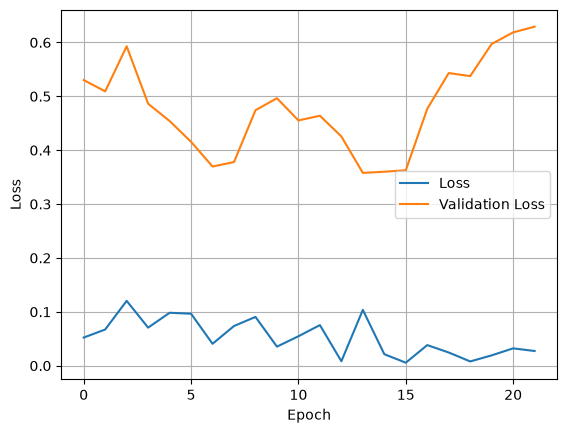

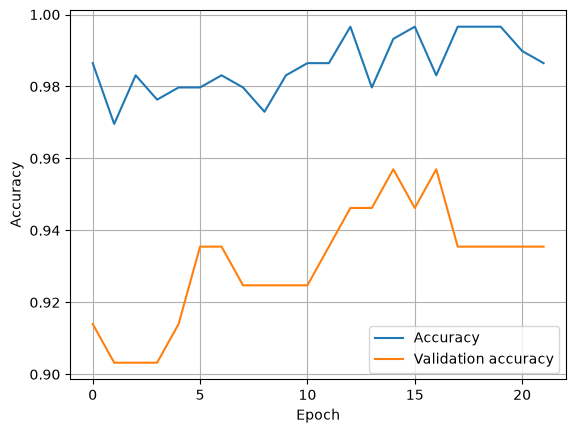

In [12]:
plt.plot(history_2.history["loss"], label="Loss")
plt.plot(history_2.history["val_loss"], label="Validation Loss")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid()
plt.show()

plt.plot(history_2.history["accuracy"], label="Accuracy")
plt.plot(history_2.history["val_accuracy"], label="Validation accuracy")
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid()
plt.show()

In [13]:
val_model_2 = keras.models.load_model("fine_tuning.keras")
val_loss, val_acc = val_model_2.evaluate(validation_dataset)

print(f"Fine tune validation accuracy: {val_acc:.3f}")
print(f"Fine tune validation loss: {val_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9462 - loss: 0.3578
Fine tune validation accuracy: 0.946
Fine tune validation loss: 0.358


## Version Tests (3.)
The table below shows the validation results for some of the tested models. Phase 1 refers to feature extraction with data augmentation. Phase 2 refers to fine-tuning the VGG16 base model by unfreezing its last four layers. Not all tested configurations are documented here. Validation scores were recorded from the model that achieved the lowest validation loss during training. The test set was not used when selecting the final model. Version 2 was selected as the final model based on its overall validation performance. 

| Test | Phase | Modification | Validation accuracy (%) | Validation loss | Training time (s) | Conclusion |
|---|---|---|---:|---:|---:|---|
| Original model | Phase 1 | - | 95.7 | 1.362 | 248.5 | The model achieved good validation accuracy, but the validation loss was quite high.|
| Original model | Phase 2 | - | 93.5 | 1.048 | 575.3 | Fine-tuning did not improve validation accuracy. Validation loss decreased, although it remained quite high.|
| Version 1 | Phase 1 | Set the learning rate to 1e-4 | 90.3 | 0.613 |640.3| Validation accuracy decreased, but validation loss improved considerably from 1.362 to 0.613  |
| Version 1| Phase 2 | - | 90.3 | 0.736 | 216.6 | Validation accuracy remained unchanged after fine-tuning, and also loss worsened a bit, although loss is still clearly lower than in the original model. Training time was also shorter than in the original model. The best performance was achieved at epoch 1, after which validation loss did not decrease further. |
| Version 2 | Phase 1| Added RandomContrast(0.1), RandomBrightness(0.1) to the data augmentation| 92.5 | 0.452 | 395.6 | Validation accuracy improved, while validation loss decreased  compared to Version 1. |
| Version 2 | Phase 2| - | 94.6 | 0.358 | 530.4 | Fine-tuning improved validation accuracy and reduced validation loss compared to Phase 1|
| Version 3 | Phase 1| Replaced Flatten() with GlobalAveragePooling2D() | 88.2 | 0.249 | 1459.8 | Training time increased a lot compared to other versions because the run used all 70 epochs and its best validation loss was at the last epoch. Validation loss decreased and reached lower value than in the previous experiments. However accuracy also decreased. Training and validation loss curves remained close together, no clear signs of overfitting. |
| Version 3 | Phase 2| - | 90.3 | 0.183 | 648.0 | Fine-tuning further reduced validation loss and increased accuracy , although accuracy remained lower than the version 2. Training time was also relatively long. |



Below are the code modifications tested in the different versions.

**Original model - Phase 1**

```python
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()


model.compile(
    optimizer=keras.optimizers.Adam(),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])


history = model.fit(
    train_dataset,
    epochs=70,
    validation_data=validation_dataset,
    callbacks=callbacks)
```

**Version 1 - Phase 1: Set the learning rate to 1e-4**

```python
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])
```


**Version 2 - Phase 1: Add RandomContrast(0.1) and RandomBrightness(0.1) to data augmentation**

```python
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),
        layers.RandomContrast(0.1),
        layers.RandomBrightness(0.1)  
    ]
)
```

**Version 3 - Phase 1: Replace Flatten() with GlobalAveragePooling2D()**

Data augmentation layer remained the same as in Version 2.

```python
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.GlobalAveragePooling2D()(x) 
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.summary()
```

## Test Performance (4.)

The final version of model that was chosen based on the validation results needs to be tested to make sure the validation results are reliable. The model should be able to achieve similar results with the test data, otherwise the model must be deemed unreliable and unsuitable for this this task.

The best version, meaning the epoch run with the lowest validation loss score, of the non-fine-tuned model was saved with ModelCheckpoint callback into the `fine_tuning_(feature_extraction).keras` file. It is loaded with the `load_model` function from `keras.model` library. The `evaluate` method predicts the target classes for images in the test_dataset and returns the calculated loss and accuracy results.

In [14]:
not_fine_tuned_model = keras.models.load_model("fine_tuning_(feature_extraction).keras")
test_loss, test_acc = not_fine_tuned_model.evaluate(test_dataset)

print(f"Test accuracy: {test_acc:.3f}")
print(f"Test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8947 - loss: 1.3308
Test accuracy: 0.895
Test loss: 1.331


The test accuracy is around 89% while the best validation accuracy was around 92%, which is not a big difference. The model seems to be able to make pretty good predictions for the new unseen data, especially compared, though the accuracy is not much higher compared to the previous model that uses the feature maps. These models are pretty much the same except this one uses data augmentation, so the lack of difference in the accuracy is sort of understandable. The validation loss was around 0.45 and the test loss is around 1.33. The difference between the validation and test loss scores is huge, but since the accuracy is not that different, it could be that the model is more confident making predictions with the test data. (There could also be a mistake in the prinouts.)

The best version final fine-tuned model was saved into the `fine_tuning.keras` file. It is loaded with the `load_model` function and tested with the `evaluate` method using the same test set.

In [15]:
fine_tuned_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = fine_tuned_model.evaluate(test_dataset)

print(f"Fine-tuned test accuracy: {test_acc:.3f}")
print(f"Fine-tuned test loss: {test_loss:.3f}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.9368 - loss: 0.9701
Fine-tuned test accuracy: 0.937
Fine-tuned test loss: 0.970


The test accuracy for the fine tuned model is around 94% while the best validation accuracy was around 95%, which is really close. The fine-tuning seems to have improved the accuracy of the model. The validation loss was around 0.36 and the test loss is around 0.97. The difference in the loss scores is still quite large. The finetuned model could be less confident in making predictions than the non-fine-tuned though since the accuracy is higher it is more likely that the model is making less incorrect predictions. 

Classification metrics are also be used to evaluate the performance of the fine tuned model. The true target class values were collected from the test dataset in to a NumPy array and the predicted target classes were obtained using the `predict` method. The `argmax` function with axis=1 parameter returns the index of the highest target class probability for each prediction. `Scikit-learn` library provides the `classification_report` function that calculates the overall `accuracy` and the `precision` and `recall` scores for each class.

In [16]:
y_true = np.concatenate([y for x, y in test_dataset], axis=0)

probs = fine_tuned_model.predict(test_dataset)
y_pred = np.argmax(probs, axis=1)

print(classification_report(y_true, y_pred, target_names=class_names))

3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step
              precision    recall  f1-score   support

        bowl       0.93      1.00      0.96        26
       glass       0.89      1.00      0.94        24
         mug       0.94      0.81      0.87        21
       plate       1.00      0.92      0.96        24

    accuracy                           0.94        95
   macro avg       0.94      0.93      0.93        95
weighted avg       0.94      0.94      0.94        95



Based on the results, the glass and bowl classes have the highest recall with 100% meaning all the images depicting the glasses and bowls are predicted correctly. The mug class has the lowest recall with 81%. Around 81% of the images depicting mugs are correctly identified. The recall for mugs seems to have gotten slightly worse compared previous feature extraction model. The plate class has the highest precision with 100% meaning that all the predictions made for the plate class are correct. The glass class has the lowest precision score with 89%. Of all the images predicted to be glasses 89% actually depict mugs.

The results can also be visualised using a confusion matrix. `Scikit-learn` library provides a function, `confusion_matrix`, for calculating the matrix and a class, `ConfusionMatrixDisplay`, for displaying a more stylised version of the matrix.

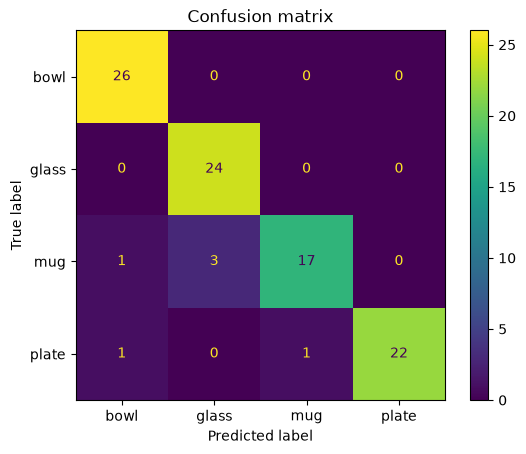

In [17]:
cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot()
plt.title("Confusion matrix")
plt.show()

The classification metrics can also be calculated from the confusion matrix. The confusion matrix also shows why some classes have lower or higher precision and recall scores. The matrix shows the predcited and true labels for each input image. The model correctly identifies glass and bowl images. Some of the mugs are predicted to be glasses and bowls explaining the lower recall score. Identifuing all the mug images seem to be difficult for all the models. 

The following code shuffles the images in the test dataset by first unbatching them and after shuffling batching them again. After obtaining the predictions, the images are displayed with their correct class labels and the probability distributions. This way the results and the performance of the model can be analysed more.

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


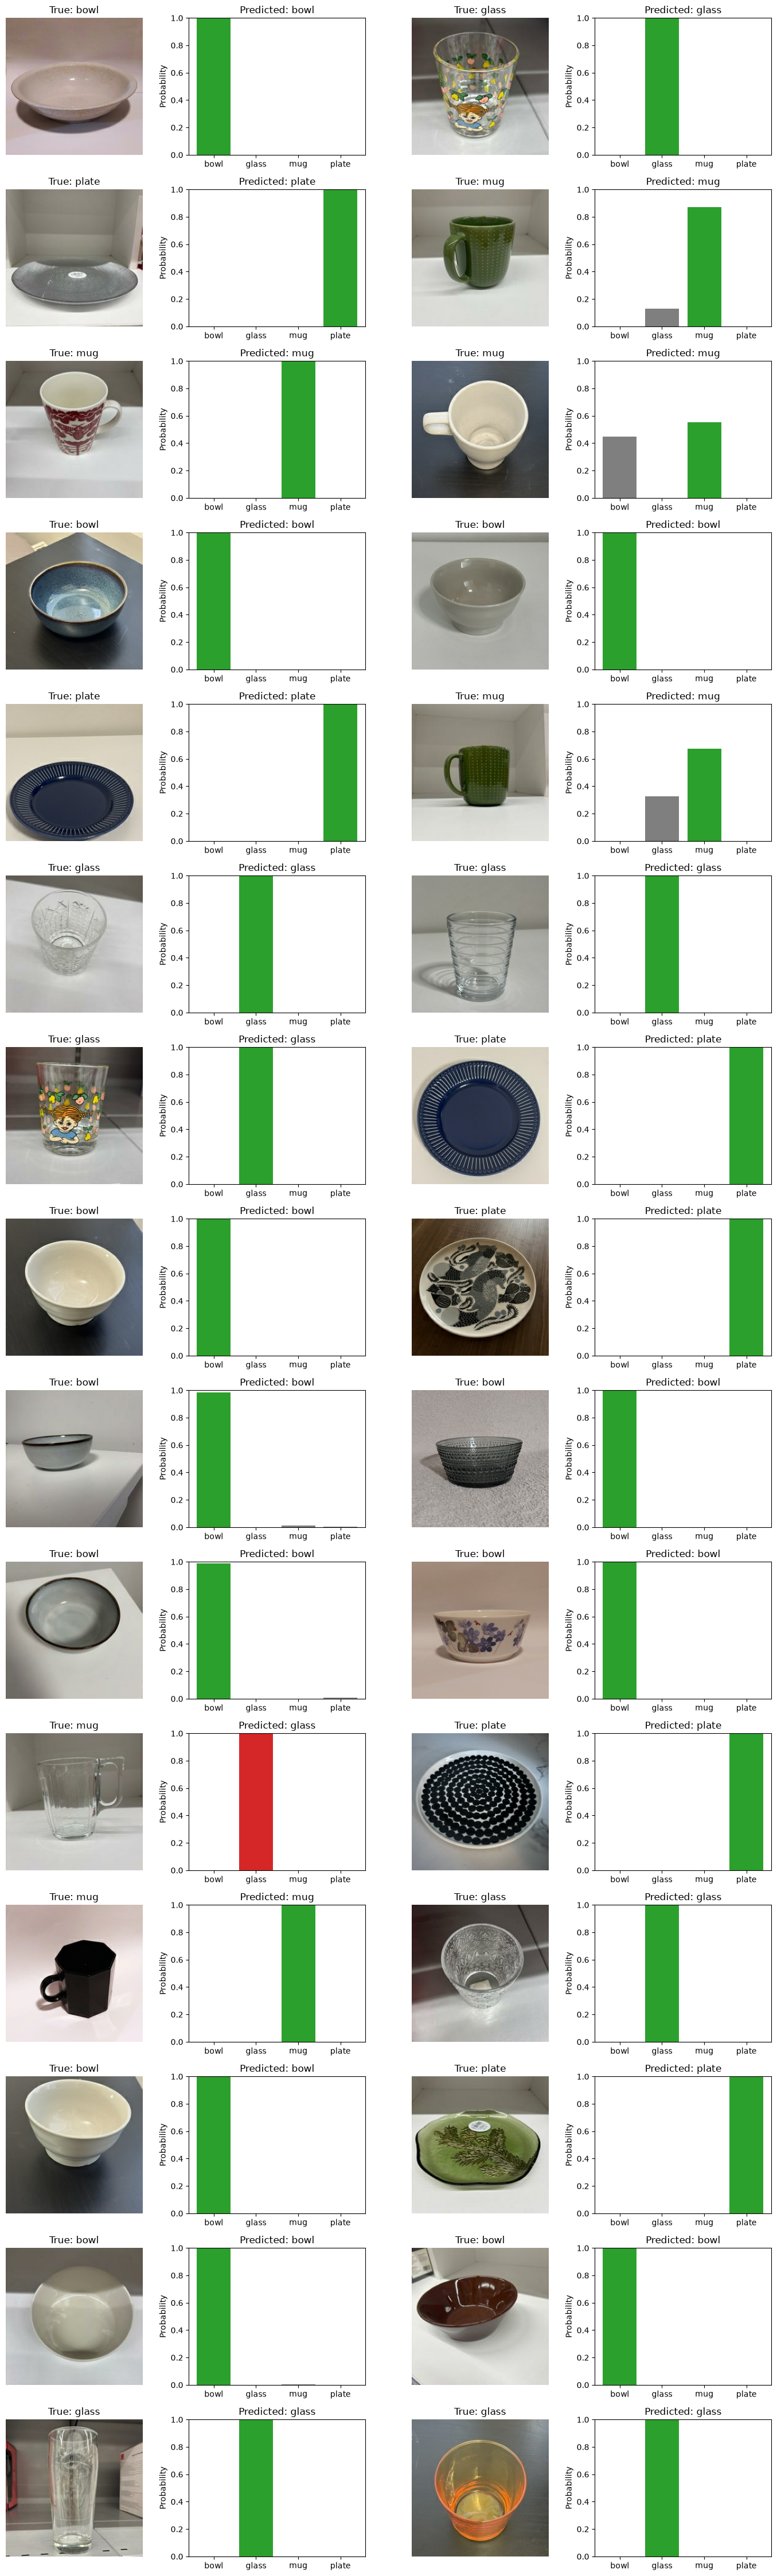

In [18]:
#x, y = next(iter(test_dataset)) 
'''
batch_index = 1

for i, (x, y) in enumerate(test_dataset):
    if i == batch_index:
        break
        
probs = test_model.predict(x)
'''

start = 0
images_n = 30
rows = images_n // 2

x, y = next(iter(test_dataset.unbatch().shuffle(1000).batch(images_n)))
probs = fine_tuned_model.predict(x)

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

The model seems to be even more confident in making the predictions as there is very little spreading out in the predictions. The example images that the previous model struggled to correctly predict are now correctly identified, apart from always confusing clear glass mug. All of the three bluish gray bowls are identified as bowls.

Since only a portion of the test images are displayed above it is hard to find the cause for the unidentified mug images. Looking through the test dataset, there seems to be another image with a clear glass mug and since the first one seems to be confusing this other might also as confusing. Some of the mugs are also photographed from an angle where the handle is not distinctly on the side so it can hard to be identified.